# Paper premise test: raw, offline build-up, and offline plus online augmentation (ST-GCN, one run each)

A scratch experiment kept outside the numbered notebooks. It tests the premise of the paper on the final ST-GCN: does building
the small classes up with synthetic clips, and then adding online augmentation on top, change the results, especially
**mean class accuracy (MCA)** and **per class F1**?

| arm | training set | online augmentation | class balancing |
|---|---|---|---|
| `raw` | the dataset as it is, natural class frequencies | none | none |
| `offline_basic` | classes under 500 clips built up to 500 with synthetic clips (basic family, fixed, written once) | none | none (already balanced) |
| `offline_basic_online_advanced` | the same enlarged set | advanced bundle, fresh every epoch, applied to every training clip including the synthetic ones | none |

**Configuration.** The tuned ST-GCN recipe in `configs/stgcn_recipe.json` (the one used in notebooks 06 and 14), `body_court` input,
9 blocks, no velocity channels. One seed (42) per arm. The only change from that recipe is that the **checkpoint is selected on
validation MCA** instead of validation top-1, because MCA is the target here; the rule is the same for all three arms, and
the test set is never used to choose anything. The test set is evaluated once per run and reported.

**What one run can and cannot say.** Seed to seed spread for this model is about 1 point of top-1 and 1 to 3 points of MCA, and seven
classes have only 11 to 13 test clips (one clip is about 8 points of recall), so differences of a few points between arms, and
most per class F1 differences, are not distinguishable from noise. The paired bootstrap below covers test clip sampling only, not
seed variation. Treat this as a first look; whichever pattern appears needs seeds before it goes into the paper.

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from clearml import Task
from sklearn.metrics import precision_recall_fscore_support

REPO = os.environ.get("BADMINTON_REPO", "/workspace/badminton-honours-project")
DATA = os.environ.get("BADMINTON_DATA", "/workspace/data")
OUTPUTS = os.environ.get("BADMINTON_OUTPUTS", "/workspace/outputs")
sys.path.insert(0, REPO)
import dataset as ds
from models import stgcn as stgcn_model
import training as tr

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

2.1.0+cu118 cuda NVIDIA GeForce RTX 4090


In [2]:
PROJECT = "BadmintonPoseAnalysis/experiments/paper_premise_test"
KEYPOINTS = f"{DATA}/keypoints_interp"
OFFLINE_ROOT = f"{DATA}/keypoints_offline_aug"
OUT = f"{OUTPUTS}/experiments/paper_premise_test"
os.makedirs(OUT, exist_ok=True)

SEED = 42
SPLITS = ("train", "val", "test")
NORMALISATION, USE_COURT = "body", True
NUM_WORKERS, EVAL_WORKERS = 20, 8
SELECT_METRIC = "mca"                 # the stgcn_recipe.json value is "top1"; MCA is the target of this test
OFFLINE_TARGET, RARE_THRESHOLD = 500, 150
N_BOOT = 2000

with open(f"{REPO}/configs/stgcn_recipe.json") as f:
    RECIPE = json.load(f)
print("recipe:", RECIPE)

ARMS = {
    "raw": {"policy": "none", "offline": False},
    "offline_basic": {"policy": "none", "offline": True},
    "offline_basic_online_advanced": {"policy": "advanced", "offline": True},
}
rng = np.random.RandomState(0)

recipe: {'model': 'ST-GCN', 'normalisation': 'body_court', 'selected': 'combination', 'changes_from_baseline': {'weight_decay': 0.005, 'target_per_class': 300}, 'augmentation': 'advanced', 'min_native_frames': 5, 'batch_size': 16, 'lr': 0.01, 'momentum': 0.9, 'gamma': 0.1, 'select_metric': 'top1', 'weight_decay': 0.005, 'label_smoothing': 0.0, 'schedule': 'step10', 'target_per_class': 300, 'num_epochs': 60, 'patience': 20, 'tuning': {'seeds': [11, 22], 'val_top1': 0.7612, 'baseline_val_top1': 0.7394}}


In [3]:
manifest = ds.load_filtered_manifest(f"{DATA}/split_manifest.csv", f"{DATA}/extraction_log.csv",
                                     f"{DATA}/keypoints_interp_log.csv", RECIPE["min_native_frames"])
class_names = sorted(manifest["class_name"].unique())
class_to_id = {c: i for i, c in enumerate(class_names)}
K = len(class_names)
short = [c.split("_", 1)[1] for c in class_names]
split_hash = open(f"{DATA}/split_manifest.sha256").read().split()[0]
train_counts = manifest[manifest["split"] == "train"]["class_name"].value_counts().reindex(class_names)

# the original protocol: classes under 500 training clips are built up to 500 with basic family synthetic clips
synthetic = ds.build_offline_augmented_set(manifest, KEYPOINTS, OFFLINE_ROOT, target=OFFLINE_TARGET, seed=0, policy="basic")
manifest_offline = pd.concat([manifest, synthetic], ignore_index=True)
after_counts = manifest_offline[manifest_offline["split"] == "train"]["class_name"].value_counts().reindex(class_names)

class_info = pd.DataFrame({"class": short, "train clips": train_counts.to_numpy(), "after offline": after_counts.to_numpy(),
                           "test clips": manifest[manifest["split"] == "test"]["class_name"].value_counts().reindex(class_names).to_numpy()})
rare_ids = [i for i, n in enumerate(train_counts.to_numpy()) if n < RARE_THRESHOLD]
common_ids = [i for i in range(K) if i not in rare_ids]
in_channels = stgcn_model.n_channels(USE_COURT)
forward = stgcn_model.make_forward(USE_COURT)
print(f"{len(synthetic)} synthetic clips; training set {int(train_counts.sum())} -> {int(after_counts.sum())}; "
      f"{len(rare_ids)} limited sample classes (under {RARE_THRESHOLD} training clips)")
class_info.sort_values("train clips", ascending=False).reset_index(drop=True)

manual review: dropped 4 clips
short clip rule: dropped 4 train clips with fewer than 5 real frames
7810 clips remain (train 6247, test 782, val 781)
3913 synthetic clips; training set 6247 -> 10160; 8 limited sample classes (under 150 training clips)


,class,train clips,after offline,test clips
0,Long Serve,791,791,99
1,Clear,755,755,95
2,Short Serve,703,703,88
3,Smash,657,657,82
4,Drop Shot,650,650,81
5,Lift,604,604,76
6,Cut,468,500,59
7,Push Shot,320,500,40
8,Flat Shot,262,500,32
9,Block,252,500,31


## Smoke test

Synthetic clips load through the normal dataset class and differ from their parents, the enlarged set reaches 500 per small
class and leaves the validation and test sets untouched, online advanced augmentation really changes a synthetic clip from draw
to draw, and one training step runs for every arm.

In [4]:
train_only = manifest[manifest["split"] == "train"]
assert synthetic["parent"].isin(train_only["filepath"]).all(), "a synthetic clip has a non training parent"
small = train_counts < OFFLINE_TARGET
assert (after_counts[small] == OFFLINE_TARGET).all() and (after_counts[~small] == train_counts[~small]).all()
for s in ("val", "test"):
    assert (manifest_offline["split"] == s).sum() == (manifest["split"] == s).sum()

row = synthetic.sample(1, random_state=0).iloc[0]
stem = os.path.splitext(os.path.basename(row["filepath"]))[0]
parent = os.path.splitext(os.path.basename(row["parent"]))[0]
syn_clip = np.load(f"{OFFLINE_ROOT}/{row['class_name']}/{stem}.npy")
par_clip = np.load(f"{KEYPOINTS}/{row['class_name']}/{parent}.npy")
assert syn_clip.shape == (30, 17, 3) and not np.array_equal(syn_clip, par_clip)

one = manifest_offline[manifest_offline["filepath"] == row["filepath"]].reset_index(drop=True)
d = ds.BadmintonPoseDataset(one, KEYPOINTS, class_to_id, "advanced", NORMALISATION)
draws = [np.asarray(d[0]["keypoints"]) for _ in range(6)]
assert any(not np.array_equal(draws[0], x) for x in draws[1:]), "online augmentation did nothing to a synthetic clip"

tr.seed_everything(0)
rows = []
for name, spec in ARMS.items():
    m = manifest_offline if spec["offline"] else manifest
    loaders = tr.build_loaders(m, KEYPOINTS, class_to_id, spec["policy"], NORMALISATION, seed=0,
                               batch_size=RECIPE["batch_size"], target_per_class=RECIPE["target_per_class"],
                               num_workers=2, eval_workers=2, balanced=False)
    batch = next(iter(loaders["train"]))
    model = stgcn_model.build_stgcn(in_channels, K).to(device)
    logits = forward(model, batch, device)
    assert logits.shape == (RECIPE["batch_size"], K)
    nn.CrossEntropyLoss()(logits, batch["label"].to(device)).backward()
    n_train = len(loaders["train"].dataset)
    rows.append({"arm": name, "training clips": n_train, "steps per epoch": len(loaders["train"]), "parameters": sum(p.numel() for p in model.parameters())})
    del model, loaders
print(pd.DataFrame(rows).to_string(index=False))
print("smoke test passed")

                          arm  training clips  steps per epoch  parameters
                          raw            6247              391     3028283
                offline_basic           10160              635     3028283
offline_basic_online_advanced           10160              635     3028283
smoke test passed


In [5]:
results_path = f"{OUT}/results.csv"
done = pd.read_csv(results_path) if os.path.exists(results_path) else pd.DataFrame(columns=["arm", "seed"])

for arm, spec in ARMS.items():
    if ((done["arm"] == arm) & (done["seed"] == SEED)).any():
        print(f"skip {arm}, already done")
        continue
    run_name = f"stgcn_premise_{arm}_s{SEED}"
    print(f"\n=== {run_name}  {spec} ===")
    tr.seed_everything(SEED)
    task = Task.init(project_name=PROJECT, task_name=run_name, task_type=Task.TaskTypes.training,
                     tags=["paper_premise_test", arm, "stgcn", f"seed{SEED}"], reuse_last_task_id=False,
                     auto_connect_frameworks={"matplotlib": False, "pytorch": False})
    task.connect({**RECIPE, **spec, "arm": arm, "seed": SEED, "select_metric": SELECT_METRIC, "balanced": False,
                  "offline_target": OFFLINE_TARGET, "keypoints": KEYPOINTS, "split_sha256": split_hash})
    m = manifest_offline if spec["offline"] else manifest
    loaders = tr.build_loaders(m, KEYPOINTS, class_to_id, spec["policy"], NORMALISATION, seed=SEED,
                               batch_size=RECIPE["batch_size"], target_per_class=RECIPE["target_per_class"],
                               num_workers=NUM_WORKERS, eval_workers=EVAL_WORKERS, balanced=False)
    model = stgcn_model.build_stgcn(in_channels, K).to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=RECIPE["lr"], momentum=RECIPE["momentum"],
                                weight_decay=RECIPE["weight_decay"])
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=RECIPE["gamma"])
    criterion = nn.CrossEntropyLoss(label_smoothing=RECIPE["label_smoothing"])
    _, history, best_epoch = tr.train_model(model, forward, loaders, optimizer, scheduler, criterion, device,
                                            task.get_logger(), num_epochs=RECIPE["num_epochs"],
                                            patience=RECIPE.get("patience", 20), select_metric=SELECT_METRIC,
                                            splits=SPLITS)
    metrics = tr.report_run(task, model, forward, loaders, class_names, device, history, best_epoch,
                            out_dir=f"{OUT}/{run_name}", run_name=run_name, splits=SPLITS, show=False,
                            extra={"arm": arm, "seed": SEED})
    task.close()
    done = pd.concat([done, pd.DataFrame([metrics])], ignore_index=True)
    done.to_csv(results_path, index=False)
    del model, loaders
    torch.cuda.empty_cache()


=== stgcn_premise_raw_s42  {'policy': 'none', 'offline': False} ===
ClearML Task: created new task id=4403caa3e54f48ab9c7b76d50818efc4
2026-10-08 04:25:08,393 - clearml.Repository Detection - WARNING - Failed accessing the jupyter server(s): []
ClearML results page: https://app.clear.ml/projects/fe4553691bdd448cad7d093b368fb533/tasks/4403caa3e54f48ab9c7b76d50818efc4/output/log
epoch   0  loss 1.811  train 0.590  val 0.583 (mca 0.431)  *
epoch   2  loss 1.283  train 0.667  val 0.661 (mca 0.470)  *
epoch   3  loss 1.214  train 0.641  val 0.624 (mca 0.472)  *
epoch   4  loss 1.177  train 0.695  val 0.684 (mca 0.511)  *
epoch   5  loss 1.144  train 0.675  val 0.640 (mca 0.470)
epoch   6  loss 1.124  train 0.702  val 0.681 (mca 0.518)  *
epoch   8  loss 1.108  train 0.717  val 0.689 (mca 0.528)  *
epoch  10  loss 0.905  train 0.773  val 0.723 (mca 0.580)  *
epoch  11  loss 0.835  train 0.782  val 0.744 (mca 0.607)  *
epoch  14  loss 0.737  train 0.818  val 0.731 (mca 0.611)  *
epoch  15  l

███████████████████████████████ 100% | 11.66/11.66 MB [00:02<00:00,  4.72MB/s]: 



=== stgcn_premise_offline_basic_s42  {'policy': 'none', 'offline': True} ===


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=78471940caee4acbaa3ddaae55a1a780
ClearML results page: https://app.clear.ml/projects/fe4553691bdd448cad7d093b368fb533/tasks/78471940caee4acbaa3ddaae55a1a780/output/log
epoch   0  loss 1.975  train 0.506  val 0.552 (mca 0.493)  *
epoch   1  loss 1.539  train 0.567  val 0.604 (mca 0.517)  *
epoch   2  loss 1.399  train 0.556  val 0.552 (mca 0.523)  *
epoch   3  loss 1.293  train 0.656  val 0.679 (mca 0.578)  *
epoch   5  loss 1.221  train 0.666  val 0.658 (mca 0.582)  *
epoch  10  loss 0.895  train 0.785  val 0.704 (mca 0.615)  *
epoch  11  loss 0.785  train 0.803  val 0.717 (mca 0.638)  *
epoch  12  loss 0.730  train 0.827  val 0.729 (mca 0.644)  *
epoch  15  loss 0.613  train 0.862  val 0.731 (mca 0.644)
epoch  19  loss 0.479  train 0.917  val 0.716 (mca 0.653)  *
epoch  20  loss 0.336  train 0.961  val 0.734 (mca 0.639)
epoch  25  loss 0.212  train 0.988  val 0.720 (mca 0.621)
epoch  30  loss 0.150  train 0.995  val 0.736 (mca 0.643)
epoch  35  loss 0

███████████████████████████████ 100% | 11.66/11.66 MB [00:02<00:00,  4.55MB/s]: 



=== stgcn_premise_offline_basic_online_advanced_s42  {'policy': 'advanced', 'offline': True} ===


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=8a4650c4ad5946d980374f3bad6ba948
ClearML results page: https://app.clear.ml/projects/fe4553691bdd448cad7d093b368fb533/tasks/8a4650c4ad5946d980374f3bad6ba948/output/log
epoch   0  loss 2.035  train 0.454  val 0.503 (mca 0.457)  *
epoch   1  loss 1.583  train 0.568  val 0.607 (mca 0.517)  *
epoch   2  loss 1.441  train 0.536  val 0.517 (mca 0.521)  *
epoch   3  loss 1.345  train 0.645  val 0.671 (mca 0.575)  *
epoch   5  loss 1.267  train 0.672  val 0.662 (mca 0.585)  *
epoch   9  loss 1.203  train 0.630  val 0.658 (mca 0.591)  *
epoch  10  loss 0.945  train 0.775  val 0.707 (mca 0.609)  *
epoch  11  loss 0.842  train 0.794  val 0.702 (mca 0.615)  *
epoch  12  loss 0.797  train 0.817  val 0.726 (mca 0.628)  *
epoch  13  loss 0.754  train 0.830  val 0.736 (mca 0.644)  *
epoch  15  loss 0.688  train 0.849  val 0.734 (mca 0.633)
epoch  20  loss 0.438  train 0.934  val 0.740 (mca 0.642)
epoch  21  loss 0.378  train 0.946  val 0.743 (mca 0.646)  *
epoch  23  

███████████████████████████████ 100% | 11.67/11.67 MB [00:03<00:00,  3.78MB/s]: 


## Results

Everything below is computed from the saved per clip test predictions, so all arms are treated identically. Checkpoints were
selected on validation MCA; the test set only reports.

In [6]:
def read_split(arm, split):
    p = pd.read_csv(f"{OUT}/stgcn_premise_{arm}_s{SEED}/stgcn_premise_{arm}_s{SEED}_predictions.csv")
    p = p[p["split"] == split].sort_values("filepath").reset_index(drop=True)
    top5 = np.array([lab in t.split(";") for lab, t in zip(p["label"], p["top5"].fillna(""))])
    return p["filepath"].to_numpy(), p["label"].map(class_to_id).to_numpy(), p["pred"].map(class_to_id).to_numpy(), top5


test, val = {}, {}
for arm in ARMS:
    test[arm] = read_split(arm, "test")
    val[arm] = read_split(arm, "val")
labels = test["raw"][1]
assert all((test[a][0] == test["raw"][0]).all() and (test[a][1] == labels).all() for a in ARMS)


def metrics_from(pred, y, top5=None):
    p, r, f1, n = precision_recall_fscore_support(y, pred, labels=list(range(K)), zero_division=0)
    out = {"top1": (pred == y).mean(), "mca": r.mean(), "macro_f1": f1.mean(),
           "limited sample recall": r[rare_ids].mean(), "common recall": r[common_ids].mean(),
           "limited sample f1": f1[rare_ids].mean(), "common f1": f1[common_ids].mean()}
    if top5 is not None:
        out["top5"] = top5.mean()
    return out, p, r, f1, n


rows, per_class_f1, per_class_recall, per_class_precision = [], {}, {}, {}
for arm in ARMS:
    m, p, r, f1, n = metrics_from(test[arm][2], labels, test[arm][3])
    mv = metrics_from(val[arm][2], val[arm][1], val[arm][3])[0]
    per_class_f1[arm], per_class_recall[arm], per_class_precision[arm] = f1, r, p
    rows.append({"arm": arm, "test top1": m["top1"], "test top5": m["top5"], "test mca": m["mca"], "test macro f1": m["macro_f1"],
                 "limited sample recall": m["limited sample recall"], "common recall": m["common recall"],
                 "limited sample f1": m["limited sample f1"], "val mca (selection)": mv["mca"], "val top1": mv["top1"]})
summary = pd.DataFrame(rows).set_index("arm")
train_top1 = pd.read_csv(results_path).set_index("arm")["train_top1"]
summary["train top1"] = train_top1.reindex(summary.index)
summary["best epoch"] = pd.read_csv(results_path).set_index("arm")["best_epoch"].reindex(summary.index)
show = summary.copy()
for c in show.columns:
    if c != "best epoch":
        show[c] = (100 * show[c]).round(2)
print(f"{len(labels)} test clips; {len(rare_ids)} limited sample classes ({int(class_info['test clips'][rare_ids].sum())} test clips)")
show

782 test clips; 8 limited sample classes (99 test clips)


,test top1,test top5,test mca,test macro f1,limited sample recall,common recall,limited sample f1,val mca (selection),val top1,train top1,best epoch
arm,,,,,,,,,,,
raw,70.59,93.73,56.41,57.77,40.63,69.04,47.11,63.92,74.90,93.52,25.0
offline_basic,67.90,94.25,57.84,57.58,50.75,63.50,49.45,65.25,71.57,91.67,19.0
offline_basic_online_advanced,72.38,94.76,61.79,63.40,54.23,67.83,60.11,67.24,76.70,98.57,54.0


In [7]:
# paired bootstrap over test clips: each arm against raw (test clip sampling only, one seed)
rows = []
for arm in ("offline_basic", "offline_basic_online_advanced"):
    for metric in ("top1", "mca", "macro_f1", "limited sample recall"):
        diffs = []
        for _ in range(N_BOOT):
            idx = np.concatenate([rng.choice(np.where(labels == k)[0], (labels == k).sum()) for k in range(K)])
            a = metrics_from(test[arm][2][idx], labels[idx])[0][metric]
            b = metrics_from(test["raw"][2][idx], labels[idx])[0][metric]
            diffs.append(a - b)
        point = metrics_from(test[arm][2], labels)[0][metric] - metrics_from(test["raw"][2], labels)[0][metric]
        lo, hi = np.percentile(diffs, [2.5, 97.5])
        rows.append({"arm": arm, "metric": metric, "difference vs raw (pts)": round(100 * point, 2),
                     "95% CI": f"[{100 * lo:+.1f}, {100 * hi:+.1f}]", "clear": bool(lo > 0 or hi < 0)})
paired = pd.DataFrame(rows)
paired

,arm,metric,difference vs raw (pts),95% CI,clear
0,offline_basic,top1,-2.69,"[-5.4, +0.1]",False
1,offline_basic,mca,1.42,"[-2.4, +5.4]",False
2,offline_basic,macro_f1,-0.19,"[-4.0, +4.1]",False
3,offline_basic,limited sample recall,10.13,"[+2.7, +17.9]",True
4,offline_basic_online_advanced,top1,1.79,"[-0.9, +4.2]",False
5,offline_basic_online_advanced,mca,5.37,"[+1.3, +10.0]",True
6,offline_basic_online_advanced,macro_f1,5.63,"[+1.1, +10.0]",True
7,offline_basic_online_advanced,limited sample recall,13.61,"[+5.5, +22.4]",True


## Per class F1

In [8]:
f1_table = pd.DataFrame({"train clips": class_info["train clips"].to_numpy(), "after offline": class_info["after offline"].to_numpy(),
                         "test clips": class_info["test clips"].to_numpy()}, index=short)
for arm in ARMS:
    f1_table[f"F1 {arm}"] = 100 * per_class_f1[arm]
f1_table["offline - raw"] = f1_table["F1 offline_basic"] - f1_table["F1 raw"]
f1_table["offline+advanced - raw"] = f1_table["F1 offline_basic_online_advanced"] - f1_table["F1 raw"]
f1_table["limited sample"] = [k in rare_ids for k in range(K)]
f1_table = f1_table.sort_values("train clips", ascending=False)
print("per class F1 on the test set (points); classes with 11 to 13 test clips swing by several points per clip")
f1_table.round(1)

per class F1 on the test set (points); classes with 11 to 13 test clips swing by several points per clip


,train clips,after offline,test clips,F1 raw,F1 offline_basic,F1 offline_basic_online_advanced,offline - raw,offline+advanced - raw,limited sample
Long Serve,791,791,99,95.0,94.6,96.4,-0.5,1.4,False
Clear,755,755,95,77.2,72.7,75.7,-4.5,-1.6,False
Short Serve,703,703,88,95.0,96.1,97.8,1.1,2.8,False
Smash,657,657,82,81.2,71.1,83.2,-10.0,2.1,False
Drop Shot,650,650,81,72.7,72.7,73.6,0.0,0.8,False
Lift,604,604,76,61.1,60.8,57.9,-0.3,-3.2,False
Cut,468,500,59,65.6,60.6,66.7,-5.0,1.1,False
Push Shot,320,500,40,35.2,36.8,34.1,1.6,-1.1,False
Flat Shot,262,500,32,24.6,19.2,13.3,-5.3,-11.2,False
Block,252,500,31,55.4,56.1,61.8,0.7,6.3,False


In [9]:
recall_table = pd.DataFrame({f"recall {a}": 100 * per_class_recall[a] for a in ARMS}, index=short)
precision_table = pd.DataFrame({f"precision {a}": 100 * per_class_precision[a] for a in ARMS}, index=short)
pd.concat([f1_table[["train clips", "test clips"]], recall_table, precision_table], axis=1).loc[f1_table.index].round(1)

,train clips,test clips,recall raw,recall offline_basic,recall offline_basic_online_advanced,precision raw,precision offline_basic,precision offline_basic_online_advanced
Long Serve,791,99,97.0,97.0,96.0,93.2,92.3,96.9
Clear,755,95,76.8,67.4,73.7,77.7,79.0,77.8
Short Serve,703,88,96.6,97.7,98.9,93.4,94.5,96.7
Smash,657,82,84.1,64.6,87.8,78.4,79.1,79.1
Drop Shot,650,81,74.1,74.1,79.0,71.4,71.4,68.8
Lift,604,76,57.9,59.2,60.5,64.7,62.5,55.4
Cut,468,59,67.8,67.8,67.8,63.5,54.8,65.6
Push Shot,320,40,40.0,40.0,37.5,31.4,34.0,31.2
Flat Shot,262,32,21.9,15.6,9.4,28.0,25.0,23.1
Block,252,31,74.2,51.6,67.7,44.2,61.5,56.8


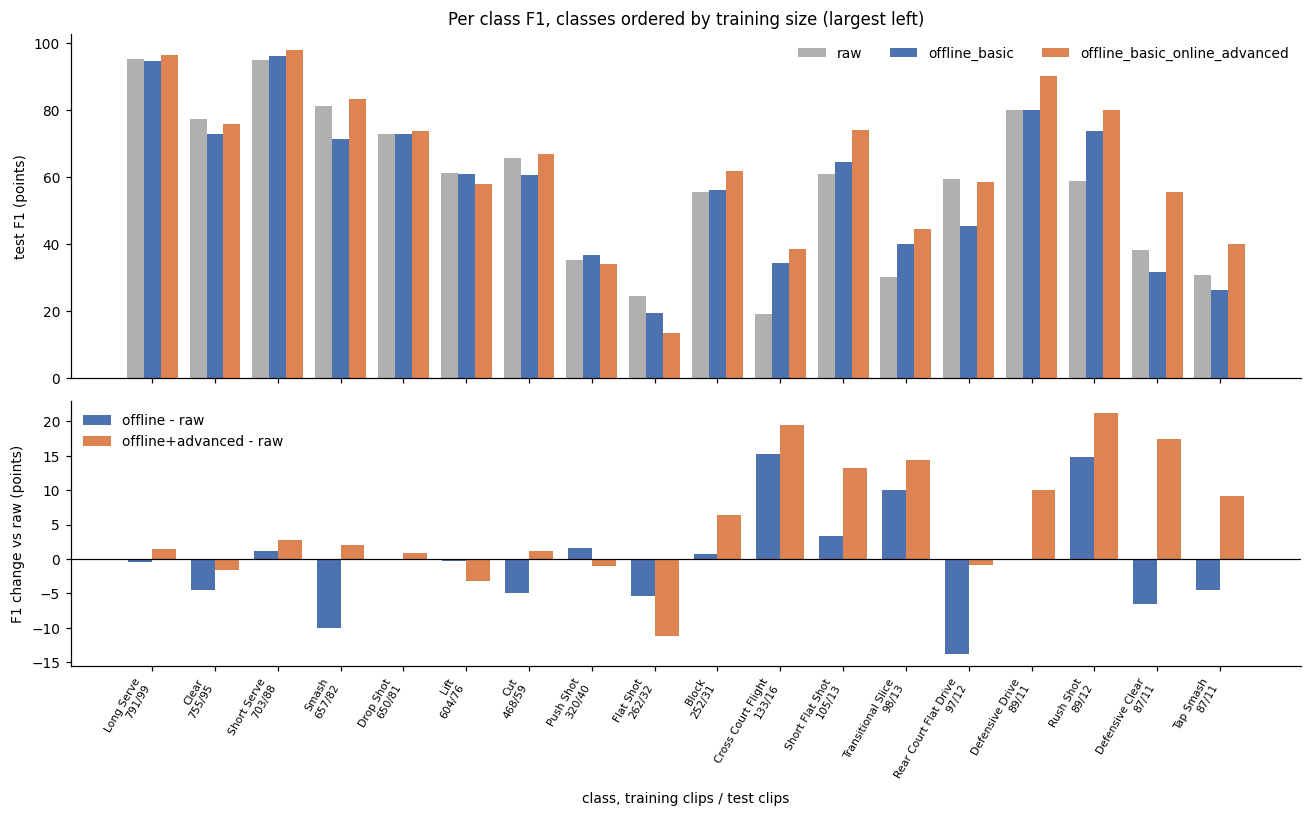

In [10]:
order = list(f1_table.index)
fig, axes = plt.subplots(2, 1, figsize=(12, 7.5), gridspec_kw={"height_ratios": [1.3, 1]}, sharex=True)
x = np.arange(K)
colors = {"raw": "#b0b0b0", "offline_basic": "#4c72b0", "offline_basic_online_advanced": "#dd8452"}
for i, arm in enumerate(ARMS):
    axes[0].bar(x + (i - 1) * 0.27, f1_table.loc[order, f"F1 {arm}"], 0.27, label=arm, color=colors[arm])
axes[0].set_ylabel("test F1 (points)")
axes[0].set_title("Per class F1, classes ordered by training size (largest left)")
axes[0].legend(frameon=False, ncol=3)
for i, col in enumerate(("offline - raw", "offline+advanced - raw")):
    axes[1].bar(x + (i - 0.5) * 0.38, f1_table.loc[order, col], 0.38, label=col, color=("#4c72b0", "#dd8452")[i])
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_ylabel("F1 change vs raw (points)")
axes[1].legend(frameon=False)
axes[1].set_xticks(x, [f"{n}\n{int(f1_table.loc[n, 'train clips'])}/{int(f1_table.loc[n, 'test clips'])}" for n in order], rotation=60, ha="right", fontsize=7)
axes[1].set_xlabel("class, training clips / test clips")
fig.tight_layout()
plt.show()

In [11]:
task = Task.init(project_name=PROJECT, task_name="paper_premise_summary", task_type=Task.TaskTypes.qc,
                 tags=["paper_premise_test", "summary"], reuse_last_task_id=False, auto_connect_frameworks={"matplotlib": False})
log = task.get_logger()
task.connect({**RECIPE, "seed": SEED, "select_metric": SELECT_METRIC, "arms": ARMS, "offline_target": OFFLINE_TARGET,
              "rare_threshold": RARE_THRESHOLD, "split_sha256": split_hash})
log.report_table("test summary", "test", iteration=0, table_plot=show.reset_index())
log.report_table("paired bootstrap vs raw", "test", iteration=0, table_plot=paired)
log.report_table("per class F1", "test", iteration=0, table_plot=f1_table.round(1).reset_index().rename(columns={"index": "class"}))
log.report_matplotlib_figure("per class F1", "test", figure=fig, iteration=0, report_interactive=False)
f1_table.to_csv(f"{OUT}/per_class_f1.csv")
show.to_csv(f"{OUT}/summary.csv")
task.upload_artifact("per_class_f1", artifact_object=f"{OUT}/per_class_f1.csv")
task.upload_artifact("summary", artifact_object=f"{OUT}/summary.csv")
task.close()

Failed accessing the jupyter server(s): []


ClearML Task: created new task id=b23533321b7e4a3987e7ca4fb9f1e6ed
ClearML results page: https://app.clear.ml/projects/fe4553691bdd448cad7d093b368fb533/tasks/b23533321b7e4a3987e7ca4fb9f1e6ed/output/log


## How to read this

- **Top-1.** Earlier multi seed work found the arms within about 0.8 points of each other on top-1. A repeat here is a consistency
  check, not new evidence.
- **MCA and limited sample recall.** These are where the premise lives: balancing or augmenting the small classes should raise
  them. With one seed, a gap under about 3 points of MCA is inside seed noise (earlier seed spread: 0.4 to 2.8 points).
- **Per class F1.** Read the pattern across classes (do the small classes move together, in the same direction, for both augmented
  arms?) more than any one class. Classes with 11 to 13 test clips change by several F1 points per clip.
- **Offline against offline plus advanced.** The only difference is online augmentation stacked on the fixed synthetic clips, so this
  pair isolates what the online bundle adds once the classes are already built up.
- **Before writing anything up**, run more seeds on whichever contrast looks real (3 reporting seeds minimum, 5 preferred) and
  report mean and spread; keep the raw arm in every table as an unaltered baseline.